# 03. Logistic Regression

- Purpose: train logistic regression models to detect moderate or worse depression and compare them with the PHQ-2 baseline.
- Input: `../data/train.csv` and `../data/test.csv`
- Output: none (results are reported in this notebook)
- Next notebook: `04` (decision tree), to be created

## Table of Contents

1. Setup and Data Loading
2. Baseline: The PHQ-2 Rule
3. Basic Logistic Regression
4. Balanced Logistic Regression
5. ROC-AUC
6. Threshold Tuning
7. Results Comparison
8. Coefficients
9. Conclusion

## 1. Setup and Data Loading

### 1.1 Importing Libraries

Besides pandas, numpy and the plotting libraries, this notebook imports the logistic regression model and the metrics used to judge it.

In [1]:
#necessary imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, recall_score, precision_score
from sklearn.model_selection import cross_val_predict

### 1.2 Loading the Training and Test Sets

The files created in notebook 02 are loaded. Using the saved split means this model is trained and tested on exactly the same students as every other model in the project.

In [2]:
#loading the train and test sets
train = pd.read_csv('../data/train.csv')
test = pd.read_csv('../data/test.csv')

In [3]:
#separating the features (X) from the target (y)
X_train = train.drop(columns='depressed')
y_train = train['depressed']
X_test = test.drop(columns='depressed')
y_test = test['depressed']

features = X_train.columns.tolist()

In [4]:
#checking the sizes
print(X_train.shape)
print(X_test.shape)
print(len(features))
print(y_test.sum())

(15400, 21)
(3851, 21)
21
257


#### Observation

The training set has 15,400 students and the test set has 3,851, each with 21 features. The test set contains 257 depressed students. All results below are measured on these 257 students, so each missed or caught student changes recall by about 0.4 percentage points.

## 2. Baseline: The PHQ-2 Rule

Any model has to be compared with the simple rule it is meant to improve on. The PHQ-2 rule adds the answers to the first two PHQ-9 questions and flags a student as depressed when the sum is 3 or more. It is applied to the same test set.

The results are shown as a confusion matrix and a classification report. The confusion matrix has this layout, where rows are the true classes and columns are the predictions:

| | Predicted not depressed | Predicted depressed |
|---|---|---|
| Actually not depressed | correct (top-left) | false alarm (top-right) |
| Actually depressed | missed (bottom-left) | caught (bottom-right) |

The bottom-left number is the most important one for a screening tool: it counts depressed students who were not identified. In the classification report, the row labelled 1 is the depressed class, and its recall is the share of depressed students who were caught.

In [5]:
#phq-2 rule on the test set: score of 3 or more = depressed
baseline_pred = ((X_test['phq_q1'] + X_test['phq_q2']) >= 3).astype(int)

print(confusion_matrix(y_test, baseline_pred))
print(classification_report(y_test, baseline_pred))

[[3481  113]
 [  85  172]]
              precision    recall  f1-score   support

           0       0.98      0.97      0.97      3594
           1       0.60      0.67      0.63       257

    accuracy                           0.95      3851
   macro avg       0.79      0.82      0.80      3851
weighted avg       0.95      0.95      0.95      3851



#### Observation

The PHQ-2 rule catches 172 of the 257 depressed students (recall 0.67) and misses 85. It also raises 113 false alarms (precision 0.60). Overall accuracy is 0.95, only a little above the 0.93 that would be obtained by calling every student not depressed, so accuracy says little here. These figures (172 caught, 85 missed, 113 false alarms) are the baseline that the logistic regression models need to beat.

## 3. Basic Logistic Regression

A standard logistic regression is fitted on the training set and used to predict the test set. `max_iter=1000` gives the solver enough iterations to converge. The model predicts "depressed" when its estimated probability is 0.5 or more.

In [6]:
#training a basic logistic regression
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

y_pred = model.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[3558   36]
 [ 111  146]]
              precision    recall  f1-score   support

           0       0.97      0.99      0.98      3594
           1       0.80      0.57      0.67       257

    accuracy                           0.96      3851
   macro avg       0.89      0.78      0.82      3851
weighted avg       0.96      0.96      0.96      3851



#### Observation

The basic model has a high accuracy of 0.96 and a precision of 0.80, with only 36 false alarms. However, it catches 146 of the 257 depressed students (recall 0.57) and misses 111, which is worse than the PHQ-2 rule (172 caught, 85 missed). Because only 6.67% of students are depressed, the model can reach a high accuracy by being cautious about predicting depression, and it does not take the cost of a missed student into account. For a screening tool this is the wrong balance.

## 4. Balanced Logistic Regression

Setting `class_weight='balanced'` makes the model treat errors on the rarer class as more costly. The weights are set in proportion to how rare each class is, so a depressed student counts for about 14 times as much as a non-depressed student in the training loss. This pushes the model to catch depressed students even if it raises more false alarms.

This matches the screening trade-off. A false alarm is cheap, because the student is simply invited to a fuller assessment. A missed student is costly, because their depression may go unnoticed and untreated.

In [7]:
#balanced: tells the model a missed depressed student costs more
model_bal = LogisticRegression(max_iter=1000, class_weight='balanced')
model_bal.fit(X_train, y_train)

y_pred_bal = model_bal.predict(X_test)
print(confusion_matrix(y_test, y_pred_bal))
print(classification_report(y_test, y_pred_bal))

[[3176  418]
 [  14  243]]
              precision    recall  f1-score   support

           0       1.00      0.88      0.94      3594
           1       0.37      0.95      0.53       257

    accuracy                           0.89      3851
   macro avg       0.68      0.91      0.73      3851
weighted avg       0.95      0.89      0.91      3851



#### Observation

The balanced model catches 243 of the 257 depressed students (recall 0.95) and misses only 14, compared with 85 missed by the PHQ-2 rule. The price is 418 false alarms (precision 0.37) and a lower accuracy of 0.89. Compared with PHQ-2 it finds 71 more depressed students at the cost of 305 more false alarms, which is roughly four extra false alarms for each additional student caught. Whether this is acceptable depends on how cheap a follow-up assessment is, which is why a middle option is explored in Section 6.

## 5. ROC-AUC

The ROC-AUC measures how well the model's predicted probabilities rank depressed students above non-depressed students, over all possible thresholds. A value of 1.0 is perfect and 0.5 is no better than guessing. It is calculated from the probabilities of the balanced model, which are also needed for threshold tuning in the next section.

In [8]:
#how well the model separates the two groups overall (1.0 = perfect, 0.5 = guessing)
y_prob = model_bal.predict_proba(X_test)[:, 1]
roc_auc_score(y_test, y_prob)

0.9739351578181534

#### Observation

The ROC-AUC is 0.974. If one depressed and one non-depressed student are picked at random, the model gives the depressed student the higher probability about 97.4% of the time. The model therefore ranks students very well, and the low precision at the default threshold of 0.5 comes mainly from where that threshold is placed and not from poor ranking.

## 6. Threshold Tuning

The default rule predicts "depressed" when the probability is at least 0.5. Raising the threshold flags fewer students, which lowers recall but also lowers the number of false alarms.

The threshold must be chosen using the training data only. If it were chosen by looking at the test results, the test set would no longer be an honest check, because the choice would be fitted to it. `cross_val_predict` provides this: it splits the training set into 5 folds, and each student receives a probability from a model that was not trained on that student.

### 6.1 Probabilities from Cross-Validation

In [9]:
#getting probabilities for the training set using 5-fold cross-validation
train_prob = cross_val_predict(model_bal, X_train, y_train, cv=5, method='predict_proba')[:, 1]

### 6.2 Trying Different Thresholds

Recall and precision on the training data are calculated for five thresholds.

In [10]:
#trying different thresholds
for t in [0.5, 0.6, 0.7, 0.8, 0.9]:
    pred = (train_prob >= t).astype(int)
    print(t, 'recall:', round(recall_score(y_train, pred), 2), 'precision:', round(precision_score(y_train, pred), 2))

0.5 recall: 0.89 precision: 0.38
0.6 recall: 0.85 precision: 0.45
0.7 recall: 0.81 precision: 0.53
0.8 recall: 0.74 precision: 0.62
0.9 recall: 0.64 precision: 0.74


#### Observation

As the threshold rises from 0.5 to 0.9, recall falls from 0.89 to 0.64 and precision rises from 0.38 to 0.74, which is the expected trade-off. At 0.8 the cross-validated recall is 0.74 and the precision is 0.62. That precision is close to the 0.60 that the PHQ-2 rule achieves, so 0.8 is a fair point at which to compare the model with PHQ-2. It was not tuned on the test set.

The app keeps the default threshold of 0.5, because it gives the highest recall (0.89 on the training data, 0.95 on the test set) and a missed student is the costliest error. The threshold of 0.8 is shown as a fair comparison with PHQ-2, since it produces about the same number of false alarms but should catch more depressed students.

### 6.3 Applying the Threshold of 0.8 to the Test Set

The threshold of 0.8 is now applied once to the test set, using the probabilities of the balanced model from Section 5.

In [11]:
#applying the chosen threshold to the test set
threshold = 0.8
y_pred_t = (y_prob >= threshold).astype(int)

print(confusion_matrix(y_test, y_pred_t))
print(classification_report(y_test, y_pred_t))

[[3478  116]
 [  57  200]]
              precision    recall  f1-score   support

           0       0.98      0.97      0.98      3594
           1       0.63      0.78      0.70       257

    accuracy                           0.96      3851
   macro avg       0.81      0.87      0.84      3851
weighted avg       0.96      0.96      0.96      3851



#### Observation

At a threshold of 0.8 the model catches 200 of the 257 depressed students (recall 0.78), misses 57 and raises 116 false alarms (precision 0.63). Compared with the PHQ-2 rule (172 caught, 85 missed, 113 false alarms), it catches 28 more depressed students for only 3 more false alarms. The test recall of 0.78 is a little above the cross-validated 0.74, which is consistent given that the test set contains only 257 depressed students.

## 7. Results Comparison

The confusion matrices above are collected into one table. The numbers are typed in from the outputs of Sections 2, 3, 4 and 6.3. "Caught" is the bottom-right value of the matrix, "missed" the bottom-left and "false_alarms" the top-right.

In [12]:
#comparing all the models on the test set
results = pd.DataFrame({
    'model': ['PHQ-2 rule', 'LR basic', 'LR balanced @0.5', 'LR balanced @0.8'],
    'caught': [172, 146, 243, 200],
    'missed': [85, 111, 14, 57],
    'false_alarms': [113, 36, 418, 116],
    'recall': [0.669, 0.568, 0.946, 0.778],
    'precision': [0.604, 0.802, 0.368, 0.633]
})
results

,model,caught,missed,false_alarms,recall,precision
0,PHQ-2 rule,172,85,113,0.669,0.604
1,LR basic,146,111,36,0.568,0.802
2,LR balanced @0.5,243,14,418,0.946,0.368
3,LR balanced @0.8,200,57,116,0.778,0.633


#### Interpretation

Each row accounts for all 257 depressed students (caught plus missed). The basic model has the fewest false alarms (36) but the lowest recall (0.568), so it is worse than the PHQ-2 rule at finding depressed students. The balanced model at 0.5 has the highest recall (0.946) and misses only 14 students, but it raises 418 false alarms. At 0.8 it beats the PHQ-2 rule on both recall (0.778 against 0.669) and precision (0.633 against 0.604) with a similar number of false alarms (116 against 113). The choice between 0.5 and 0.8 depends on how many false alarms the app and the follow-up service can tolerate.

## 8. Coefficients

Each coefficient shows how much one question pushes the prediction towards depression. A positive coefficient means that a higher answer raises the predicted probability of depression, and a negative one means the opposite. Specifically, each extra point on a question multiplies the odds of depression by e raised to the power of its coefficient. The coefficients are comparable across questions because all answers are on similar small scales (Section 5 of notebook 02). They come from the balanced model.

### 8.1 Coefficient Table

In [13]:
#how much each question pushes the prediction towards "depressed"
coefs = pd.DataFrame({'question': features, 'coefficient': model_bal.coef_[0]})
coefs = coefs.sort_values('coefficient', ascending=False)
coefs

,question,coefficient
0,phq_q2,1.819000
1,phq_q1,1.706224
12,isi_q1,0.522996
7,pss_q2,0.504208
2,gad_q6,0.458947
3,gad_q2,0.362248
10,gad_q5,0.276012
15,pss_q14,0.271774
13,isi_q7,0.264010
11,gad_q7,0.203488


#### Observation

The two PHQ-2 questions dominate: `phq_q2` has a coefficient of 1.82 and `phq_q1` has 1.71, so each extra point on them multiplies the odds of depression by about 6.2 and 5.5. They are more than three times larger than the next question, `isi_q1` (0.52). The extra questions that add the most are `isi_q1` (0.52), `pss_q2` (0.50), `gad_q6` (0.46) and `gad_q2` (0.36). Five questions have coefficients close to zero: `pss_q1` (-0.002), `pss_q3` (0.007), `pss_q8` (0.03), `pss_q11` (0.05) and `isi_q3` (0.05).

### 8.2 Coefficient Plot

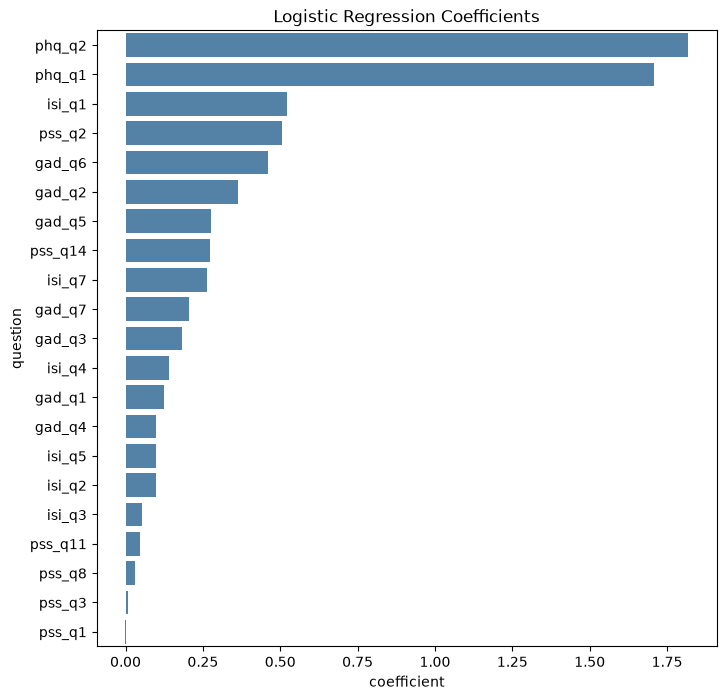

In [14]:
#plotting the coefficients
plt.figure(figsize=(8, 8))
sns.barplot(x='coefficient', y='question', data=coefs, color='steelblue')
plt.title('Logistic Regression Coefficients')
plt.show()

#### Observation

The plot shows two very long bars for `phq_q2` and `phq_q1`, a group of moderate bars from `isi_q1` down to `gad_q7`, and a long tail of short bars. `pss_q1` is the only question with a slightly negative coefficient, but it is so close to zero that it has no real effect. Two of the questions with the smallest bars, `pss_q1` and `pss_q3`, were among the stronger ones in the correlation ranking in notebook 02 (about 0.53 and 0.56 with the PHQ-9 total). Their information is already contained in other questions such as `pss_q2` and the GAD-7 items, so the model gives them almost no extra weight.

### 8.3 Intercept

In [15]:
#the intercept of the model
print(model_bal.intercept_)

[-7.88261936]


#### Observation

The intercept is -7.88. It is the starting point on the log-odds scale before any answers are added, and it is strongly negative, so a student is only predicted to be depressed when several answers are high, mainly the two PHQ-2 questions. The five near-zero coefficients above are the first candidates to drop to shorten the app from 21 to 16 questions. The model should be refitted without them, and the recall checked on the training data, before the change is made.

## 9. Conclusion

- The basic logistic regression has a high accuracy (0.96) but catches only 146 of 257 depressed students (recall 0.57), which is worse than the PHQ-2 rule (172 caught, recall 0.67). Accuracy is misleading on this imbalanced target.
- The balanced model at the default threshold of 0.5 catches 243 students (recall 0.95) and misses only 14, against 85 for PHQ-2, but it produces 418 false alarms (precision 0.37). This is the setting the app keeps, since a missed student is costlier than a false alarm.
- At a threshold of 0.8, chosen using training data only, the model has about the same false alarms as PHQ-2 (116 against 113) and catches 200 students against 172 (recall 0.78 against 0.67, precision 0.63 against 0.60), so it beats the baseline on both measures.
- The ROC-AUC is 0.974. The two PHQ-2 questions carry most of the weight, `isi_q1`, `pss_q2` and `gad_q6` add the most beyond them, and five questions have coefficients near zero and could be dropped.
- These results come from one train/test split with 257 depressed students in the test set, so small differences should be treated with caution. The decision tree, random forest and XGBoost models will be evaluated on the same files and compared with these results.